In [1]:
from pathlib import Path
import re
from typing import List, Optional
import pandas as pd
from pathlib import Path

ARQUIVO_ANALISE_RESPOSTA = Path("analise_resposta.xlsx")


def salvar_dataframe_na_aba(df: pd.DataFrame, sheet_name: str, arquivo: Path = ARQUIVO_ANALISE_RESPOSTA) -> None:
    arquivo = Path(arquivo)
    if arquivo.exists():
        with pd.ExcelWriter(arquivo, engine="openpyxl", mode="a", if_sheet_exists="replace") as writer:
            df.to_excel(writer, sheet_name=sheet_name, index=False)
    else:
        with pd.ExcelWriter(arquivo, engine="openpyxl", mode="w") as writer:
            df.to_excel(writer, sheet_name=sheet_name, index=False)

    print(f"Arquivo atualizado: {arquivo} | Aba: {sheet_name}")

In [2]:
# ========== FUNÇÕES AUXILIARES (MARKDOWN) ==========

def _is_sep_line(line: str) -> bool:
    s = line.strip()
    return bool(re.match(r'^\|?[\s:\-|]+$', s)) and ('-' in s)

def _is_table_line(line: str) -> bool:
    return '|' in line

def _normalize_row_cells(line: str) -> List[str]:
    parts = [p.strip() for p in line.split('|')]
    if parts and parts[0] == '':
        parts = parts[1:]
    if parts and parts[-1] == '':
        parts = parts[:-1]
    return parts

# ========== EXTRAÇÃO DE TABELAS ==========

def extract_markdown_tables(text: str) -> List[pd.DataFrame]:
    """Extrai todas as tabelas Markdown de um texto, retorna lista de DataFrames"""
    lines = text.splitlines()
    tables = []
    i = 0
    while i < len(lines):
        if i + 1 < len(lines) and _is_table_line(lines[i]) and _is_sep_line(lines[i+1]):
            header_line = lines[i]
            j = i + 2
            data_lines = []
            while j < len(lines):
                curr = lines[j].strip()
                if not curr:
                    j += 1
                    break
                if '|' not in curr:
                    break
                if j + 1 < len(lines) and _is_sep_line(lines[j+1]) and _is_table_line(lines[j]):
                    break
                data_lines.append(curr)
                j += 1

            headers = _normalize_row_cells(header_line)
            rows = []
            for dl in data_lines:
                cells = _normalize_row_cells(dl)
                if len(cells) < len(headers):
                    cells += [''] * (len(headers) - len(cells))
                elif len(cells) > len(headers):
                    cells = cells[:len(headers)]
                rows.append(cells)

            if rows:
                try:
                    df = pd.DataFrame(rows, columns=headers)
                    df = df.convert_dtypes()
                    tables.append(df)
                except Exception as e:
                    print(f"Erro ao criar DataFrame: {e}")
            i = j
        else:
            i += 1
    return tables

def extract_tables_from_file(path: str) -> List[pd.DataFrame]:
    """Extrai todas as tabelas de um arquivo Markdown"""
    p = Path(path)
    if not p.exists():
        print(f"Arquivo não encontrado: {path}")
        return []
    try:
        text = p.read_text(encoding='utf-8')
        return extract_markdown_tables(text)
    except Exception as e:
        print(f"Erro ao ler {path}: {e}")
        return []

# ========== NORMALIZAÇÃO INDIVIDUAL ==========

def normalize_table_structure(df: pd.DataFrame) -> pd.DataFrame:
    """
    Normaliza uma tabela para o formato padrão:
    Prática Principal | Prática Auxiliar | Tickets
    (Remove asteriscos, unifica nomes de colunas)
    """
    # Remove markdown bold (**)
    for col in df.columns:
        df[col] = df[col].map(lambda x: x.replace('**', '') if isinstance(x, str) else x)

    column_mapping = {
        'Prática Principal': 'Prática Principal',
        'Prática Principal (Prevenção/Resolução)': 'Prática Principal',
        'Prática Principal (Prevenção/Solução)': 'Prática Principal',
        'Prática Principal (Resolução)': 'Prática Principal',
        'Prática Principal Recomendada': 'Prática Principal',
        'Prática principal': 'Prática Principal',
        'Prática auxiliar': 'Prática Auxiliar',
        'Prática Auxiliar': 'Prática Auxiliar',
        'Prática Auxiliar (Apoio)': 'Prática Auxiliar',
        'Prática Auxiliar (Prevenção)': 'Prática Auxiliar',
        'Prática Auxiliar Recomendada': 'Prática Auxiliar',
        'Ticket(s) Associado(s)': 'Tickets',
        'Ticket(s)': 'Tickets',
        'Tickets Associados': 'Tickets',
        'Ticket': 'Tickets',
        'Ticket Associado': 'Tickets',
        'Ticket ID': 'Tickets',
    }
    df = df.rename(columns=column_mapping)

    # Mantém apenas as colunas padrão existentes
    desired = ['Prática Principal', 'Prática Auxiliar', 'Tickets']
    existing = [c for c in desired if c in df.columns]
    if existing:
        df = df[existing]
    return df

def remover_registros_duplicados(df: pd.DataFrame, ticket_col: str = 'Tickets', source_col: Optional[str] = None) -> pd.DataFrame:
    if df.empty:
        return df.copy()

    resultado = df.copy()

    if ticket_col in resultado.columns:
        resultado[ticket_col] = (
            resultado[ticket_col]
            .astype('string')
            .str.replace(r'\s+', ' ', regex=True)
            .str.strip()
        )

    subset = []
    if source_col and source_col in resultado.columns:
        subset.append(source_col)
    if ticket_col in resultado.columns:
        subset.append(ticket_col)

    if subset:
        resultado = resultado.drop_duplicates(subset=subset, keep='last')
    else:
        resultado = resultado.drop_duplicates(keep='last')

    return resultado.reset_index(drop=True)

# ========== JUNÇÃO OPCIONAL ==========

def merge_normalized_tables(list_of_dfs: List[pd.DataFrame],
                            add_source: bool = True,
                            source_label: str = 'Origem') -> pd.DataFrame:
    """
    Junta vários DataFrames já normalizados (após normalize_table_structure).
    add_source=True adiciona coluna com índice de origem.
    """
    if not list_of_dfs:
        return pd.DataFrame()
    all_dfs = []
    for idx, df in enumerate(list_of_dfs):
        df_temp = df.copy()
        if add_source:
            df_temp[source_label] = f"Tabela_{idx+1}"
        all_dfs.append(df_temp)
    merged = pd.concat(all_dfs, ignore_index=True, sort=False)
    # Limpeza básica
    merged = merged.replace(['<NA>', ''], pd.NA).dropna(how='all')
    # Remove linhas onde todas as colunas principais são NaN
    main_cols = ['Prática Principal', 'Prática Auxiliar', 'Tickets']
    existing_main = [c for c in main_cols if c in merged.columns]
    if existing_main:
        merged = merged.dropna(subset=existing_main, how='all')
    return merged.reset_index(drop=True)

# ========== EXPANSÃO DE TICKETS (OPCIONAL) ==========

def expand_tickets(df: pd.DataFrame) -> pd.DataFrame:
    """Transforma a coluna 'Tickets' em linhas individuais (um ticket por linha)"""
    if 'Tickets' not in df.columns:
        return df
    expanded = []
    for _, row in df.iterrows():
        raw = row['Tickets']
        if pd.isna(raw):
            expanded.append(row)
            continue
        ticket_nums = re.findall(r'#(\d+)', str(raw).replace('**', ''))
        if not ticket_nums:
            expanded.append(row)
        else:
            for num in ticket_nums:
                new_row = row.copy()
                new_row['Ticket'] = f"#{num}"
                expanded.append(new_row)
    result = pd.DataFrame(expanded)
    # Reordena colunas
    col_order = ['Ticket', 'Prática Principal', 'Prática Auxiliar', 'Tickets']
    final_cols = [c for c in col_order if c in result.columns]
    return result[final_cols]

# ========== EXEMPLO DE USO SEPARADO ==========

if __name__ == "__main__":
    # 1. Extraia tabelas de cada arquivo separadamente
    tables_rag = extract_tables_from_file("resposta_agent_rag.md")
    tables_rag_adaptativo = extract_tables_from_file("resposta_agent_rag_adaptativo.md")
    tables_chat = extract_tables_from_file("resposta_chat.md")
    tables_chat_stream = extract_tables_from_file("resposta_chat_stream.md")
    tables_file5 = extract_tables_from_file("resposta_planejar_executar.md")

    print(f"resposta_agent_rag.md: {len(tables_rag)} tabela(s)")
    print(f"resposta_agent_rag_adaptativo.md: {len(tables_rag_adaptativo)} tabela(s)")
    print(f"resposta_chat.md: {len(tables_chat)} tabela(s)")
    print(f"resposta_chat_stream.md: {len(tables_chat_stream)} tabela(s)")
    print(f"resposta_planejar_executar.md: {len(tables_file5)} tabela(s)")

    # 2. Normalize cada tabela individualmente
    norm_tables_rag = [normalize_table_structure(t) for t in tables_rag]
    norm_tables_rag_adaptativo = [normalize_table_structure(t) for t in tables_rag_adaptativo]
    norm_tables_chat_stream = [normalize_table_structure(t) for t in tables_chat_stream]
    norm_tables_chat = [normalize_table_structure(t) for t in tables_chat]
    norm_tables_planejar_executar = [normalize_table_structure(t) for t in tables_file5]


    


Arquivo não encontrado: resposta_planejar_executar.md
resposta_agent_rag.md: 9 tabela(s)
resposta_agent_rag_adaptativo.md: 15 tabela(s)
resposta_chat.md: 10 tabela(s)
resposta_chat_stream.md: 10 tabela(s)
resposta_planejar_executar.md: 0 tabela(s)


In [3]:
# ========== CHAT E CHAT STREAM ==========

df_chat_stream = merge_normalized_tables(norm_tables_chat_stream, add_source=True)
df_chat = merge_normalized_tables(norm_tables_chat, add_source=True)
df_chat_stream.drop(columns=['Origem'], inplace=True, errors='ignore')
df_chat.drop(columns=['Origem'], inplace=True, errors='ignore')

# remove o texto Ticket da coluna tickets
# df_chat_stream['Tickets'] = df_chat_stream['Tickets'].str.replace('Ticket', '').str.strip()
df_chat['Tickets'] = df_chat['Tickets'].str.replace('Ticket', '').str.strip()

In [4]:
# def _clean_tickets_cell(val):
#     if pd.isna(val):
#         return val
#     parts = [p.strip() for p in str(val).split(',')]
#     cleaned = []
#     for p in parts:
#         if not p:
#             continue
#         if p.startswith('#'):
#             p = p[1:]
#         p = p.split(':', 1)[0].strip()
#         if p:
#             cleaned.append(p)
#     return ', '.join(cleaned) if cleaned else pd.NA

# # # Limpa e expande usando a função `expand_tickets`, preservando Prática Principal e Prática Auxiliar
# df_chat_stream['Tickets'] = df_chat_stream['Tickets'].apply(_clean_tickets_cell)
# # df_chat_stream = expand_tickets(df_chat_stream)
# # # Renomeia `Ticket` para `Tickets` para compatibilidade com o restante do fluxo
# # if 'Ticket' in df_chat_stream.columns and 'Tickets' not in df_chat_stream.columns:
# #     df_chat_stream = df_chat_stream.rename(columns={'Ticket': 'Tickets'})

# # df_chat_stream.head()

In [5]:
df_rag = merge_normalized_tables(norm_tables_rag,add_source=True)
df_rag_adaptativo = merge_normalized_tables(norm_tables_rag_adaptativo,add_source=True)
df_rag.drop(columns=['Origem'], inplace=True, errors='ignore')
df_rag_adaptativo.drop(columns=['Origem'], inplace=True, errors='ignore')



In [6]:
df_plan_exec = merge_normalized_tables(norm_tables_planejar_executar,add_source=True)
df_plan_exec.drop(columns=['Origem'], inplace=True, errors='ignore')



In [7]:
# Unifica os DataFrames em um único DataFrame com a coluna "origem"

dfs_origem = {
    "chat": df_chat,
    "chat_stream": df_chat_stream,
    "rag": df_rag,
    "rag_adaptativo": df_rag_adaptativo,
    "plan_exec": df_plan_exec,
}

for nome, df in list(dfs_origem.items()):
    if isinstance(df, pd.DataFrame) and not df.empty:
        dfs_origem[nome] = remover_registros_duplicados(df, ticket_col="Tickets")

df_unificado = pd.concat(
    [
        df.copy().assign(origem=nome)
        for nome, df in dfs_origem.items()
        if df is not None and not df.empty
    ],
    ignore_index=True,
    sort=False,
)

df_unificado = remover_registros_duplicados(df_unificado, ticket_col="Tickets", source_col="origem")

df_unificado


,Prática Principal,Prática Auxiliar,Tickets,origem
0,Gerenciamento de Incidentes,Gerenciamento de Problemas,#3,chat
1,Gerenciamento de Incidentes,Gerenciamento de Mudanças,#25,chat
2,Gerenciamento de Requisição de Serviço,Gerenciamento de Relacionamento,#42,chat
3,Gerenciamento de Incidentes,Gerenciamento de Ativos de TI,#57,chat
4,Gerenciamento de Configuração de Serviço,Gerenciamento de Ativos de TI,#62,chat
...,...,...,...,...
613,Gerenciamento de Requisições,Não se aplica,#1226,rag_adaptativo
614,Gerenciamento de Requisições,Não se aplica,#1234,rag_adaptativo
615,Gerenciamento de Incidentes,Gerenciamento de Ativos de TI,#1238,rag_adaptativo
616,Gerenciamento de Problemas,Gerenciamento de Disponibilidade,#1242,rag_adaptativo


In [8]:
# Preenche colunas de prática sem valor com "SEM RECOMENDAÇÃO"
colunas_pratica = [
    c for c in df_unificado.columns
    if "Prática" in c and ("Principal" in c or "Auxiliar" in c)
]

for col in colunas_pratica:
    df_unificado[col] = (
        df_unificado[col]
        .replace(r"^\s*$", pd.NA, regex=True)
        .fillna("SEM RECOMENDAÇÃO")
    )

df_unificado[colunas_pratica].isna().sum()

Prática Principal    0
Prática Auxiliar     0
dtype: int64

In [9]:
# Remove prefixo "Ticket" no início dos valores da coluna Tickets (case-insensitive)
padrao_ticket_prefix = r"^\s*Ticket\s*"

for df in [df_chat, df_chat_stream, df_rag, df_rag_adaptativo, df_plan_exec, df_unificado]:
    if isinstance(df, pd.DataFrame) and "Tickets" in df.columns:
        df["Tickets"] = (
            df["Tickets"]
            .astype("string")
            .str.replace(padrao_ticket_prefix, "", regex=True, flags=re.IGNORECASE)
            .str.strip()
        )

df_unificado[["Tickets"]].head()

,Tickets
0,#3
1,#25
2,#42
3,#57
4,#62


In [10]:
def garantir_hash_tickets(valor):
    if pd.isna(valor):
        return valor

    partes = [p.strip() for p in str(valor).split(",") if p.strip()]
    partes_ajustadas = []

    for p in partes:
        p = p.strip()
        if not p.startswith("#"):
            p = f"#{p.lstrip('#').strip()}"
        partes_ajustadas.append(p)

    return ", ".join(partes_ajustadas)

# Aplica em todos os DataFrames que têm a coluna "Tickets"
for df in [df_chat, df_chat_stream, df_rag, df_rag_adaptativo, df_plan_exec, df_unificado]:
    if isinstance(df, pd.DataFrame) and "Tickets" in df.columns:
        df["Tickets"] = df["Tickets"].apply(garantir_hash_tickets)

df_unificado[["Tickets"]].head(10)

,Tickets
0,#3
1,#25
2,#42
3,#57
4,#62
5,#77
6,#87
7,#98
8,#104
9,#110


In [11]:
# Remove "(Service Desk)" das colunas de prática em todos os DataFrames relevantes
padrao_service_desk = r"\s*\(\s*Service\s*Desk\s*\)\s*"

for df in [df_chat, df_chat_stream, df_rag, df_rag_adaptativo, df_plan_exec, df_unificado, df_unificado]:
    if isinstance(df, pd.DataFrame) and not df.empty:
        cols_praticas = [c for c in df.columns if "Prática" in c]
        for col in cols_praticas:
            df[col] = (
                df[col]
                .astype("string")
                .str.replace(padrao_service_desk, "", regex=True, flags=re.IGNORECASE)
                .str.replace(r"\s{2,}", " ", regex=True)
                .str.strip()
            )

df_unificado[[c for c in df_unificado.columns if "Prática" in c]].head()

,Prática Principal,Prática Auxiliar
0,Gerenciamento de Incidentes,Gerenciamento de Problemas
1,Gerenciamento de Incidentes,Gerenciamento de Mudanças
2,Gerenciamento de Requisição de Serviço,Gerenciamento de Relacionamento
3,Gerenciamento de Incidentes,Gerenciamento de Ativos de TI
4,Gerenciamento de Configuração de Serviço,Gerenciamento de Ativos de TI


In [12]:
# Substitui variações de "Não se aplica" por "SEM RECOMENDAÇÃO"
padrao_nao_se_aplica = r"^\s*n[aã]o\s+se\s+aplica\s*$"

for df in [df_chat, df_chat_stream, df_rag, df_rag_adaptativo, df_plan_exec, df_unificado]:
    if isinstance(df, pd.DataFrame) and not df.empty:
        cols_praticas = [c for c in df.columns if "Prática" in c]
        if cols_praticas:
            df[cols_praticas] = df[cols_praticas].replace(
                padrao_nao_se_aplica,
                "SEM RECOMENDAÇÃO",
                regex=True
            )

# Verificação rápida no consolidado
df_unificado[[c for c in df_unificado.columns if "Prática" in c]].head()

,Prática Principal,Prática Auxiliar
0,Gerenciamento de Incidentes,Gerenciamento de Problemas
1,Gerenciamento de Incidentes,Gerenciamento de Mudanças
2,Gerenciamento de Requisição de Serviço,Gerenciamento de Relacionamento
3,Gerenciamento de Incidentes,Gerenciamento de Ativos de TI
4,Gerenciamento de Configuração de Serviço,Gerenciamento de Ativos de TI


In [13]:
# Substitui variações de "Não há recomendação" por "SEM RECOMENDAÇÃO"
padrao_nao_ha_recomendacao = r"^\s*n[aã]o\s+h[aá]\s+recomenda[cç][aã]o\.?\s*$"

for df in [df_chat, df_chat_stream, df_rag, df_rag_adaptativo, df_plan_exec, df_unificado]:
    if isinstance(df, pd.DataFrame) and not df.empty:
        cols_praticas = [c for c in df.columns if "Prática" in c]
        if cols_praticas:
            df[cols_praticas] = df[cols_praticas].replace(
                padrao_nao_ha_recomendacao,
                "SEM RECOMENDAÇÃO",
                regex=True
            )

# Verificação rápida no consolidado
df_unificado[[c for c in df_unificado.columns if "Prática" in c]].head()

,Prática Principal,Prática Auxiliar
0,Gerenciamento de Incidentes,Gerenciamento de Problemas
1,Gerenciamento de Incidentes,Gerenciamento de Mudanças
2,Gerenciamento de Requisição de Serviço,Gerenciamento de Relacionamento
3,Gerenciamento de Incidentes,Gerenciamento de Ativos de TI
4,Gerenciamento de Configuração de Serviço,Gerenciamento de Ativos de TI


In [14]:
salvar_dataframe_na_aba(df_unificado, "respostas")

Arquivo atualizado: analise_resposta.xlsx | Aba: respostas


In [15]:
# salvar_dataframe_na_aba(df_chat_stream, "resposta_chat_stream")
# salvar_dataframe_na_aba(df_chat, "resposta_chat")

# df_chat_stream.head(), df_chat.head()
# salvar_dataframe_na_aba(df_rag, "resposta_agent_rag")
# salvar_dataframe_na_aba(df_rag_adaptativo, "resposta_agent_rag_adaptativo")

# df_rag.head(), df_rag_adaptativo.head()
# salvar_dataframe_na_aba(df_plan_exec, "resposta_planejar_executar")

# df_plan_exec.head()

In [16]:
# tables_plan_exec_avaliar = extract_tables_from_file("resposta_itil_agent_plan_exec_avaliar.md")
# print(f"resposta_itil_agent_plan_exec_avaliar.md: {len(tables_plan_exec_avaliar)} tabela(s)")

# norm_tables_plan_exec_avaliar = [normalize_table_structure(t) for t in tables_plan_exec_avaliar]

# df_plan_exec_avaliar = merge_normalized_tables(norm_tables_plan_exec_avaliar, add_source=True)
# df_plan_exec_avaliar.info()

# df_plan_exec_avaliar.to_csv("resposta_itil_agent_plan_exec_avaliar.csv", index=False)
# df_plan_exec_avaliar.to_excel("resposta_itil_agent_plan_exec_avaliar.xlsx", index=False)

Resumo da avaliação por origem:


,origem,total_registros,recomendacoes_principais,sem_recomendacao_principal,recomendacoes_auxiliares,sem_recomendacao_auxiliar,cobertura_principal_pct,cobertura_auxiliar_pct,avaliacao_media_pct,sem_recomendacao_total_pct
0,rag_adaptativo,134,134,0,134,0,100.0,100.000000,100.000000,0.000000
1,rag,270,270,0,270,0,100.0,100.000000,100.000000,0.000000
2,chat_stream,102,102,0,98,4,100.0,96.078431,98.039216,1.960784
3,chat,112,112,0,95,17,100.0,84.821429,92.410714,7.589286


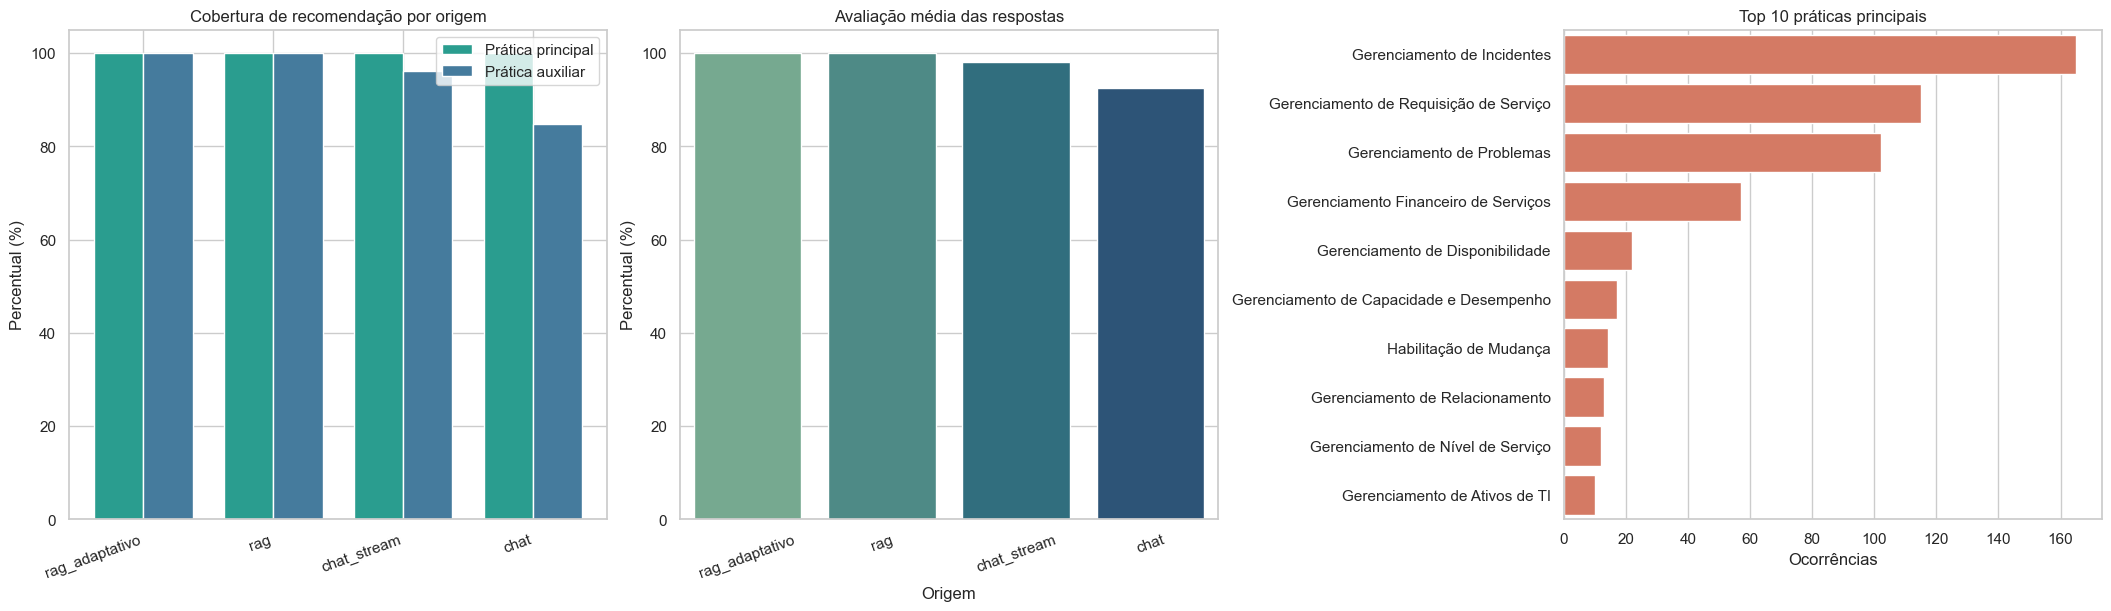

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

base_analise = df_unificado.copy()
base_analise["Prática Principal"] = base_analise["Prática Principal"].fillna("SEM RECOMENDAÇÃO").astype(str)
base_analise["Prática Auxiliar"] = base_analise["Prática Auxiliar"].fillna("SEM RECOMENDAÇÃO").astype(str)
base_analise["tem_pratica_principal"] = base_analise["Prática Principal"].ne("SEM RECOMENDAÇÃO")
base_analise["tem_pratica_auxiliar"] = base_analise["Prática Auxiliar"].ne("SEM RECOMENDAÇÃO")

resultado_resumo = (
    base_analise.groupby("origem", dropna=False)
    .agg(
        total_registros=("origem", "size"),
        recomendacoes_principais=("tem_pratica_principal", "sum"),
        sem_recomendacao_principal=("tem_pratica_principal", lambda s: (~s).sum()),
        recomendacoes_auxiliares=("tem_pratica_auxiliar", "sum"),
        sem_recomendacao_auxiliar=("tem_pratica_auxiliar", lambda s: (~s).sum()),
    )
    .reset_index()
)

resultado_resumo["cobertura_principal_pct"] = (
    resultado_resumo["recomendacoes_principais"] / resultado_resumo["total_registros"] * 100
)
resultado_resumo["cobertura_auxiliar_pct"] = (
    resultado_resumo["recomendacoes_auxiliares"] / resultado_resumo["total_registros"] * 100
)
resultado_resumo["avaliacao_media_pct"] = (
    resultado_resumo["cobertura_principal_pct"] + resultado_resumo["cobertura_auxiliar_pct"]
) / 2
resultado_resumo["sem_recomendacao_total_pct"] = (
    (resultado_resumo["sem_recomendacao_principal"] + resultado_resumo["sem_recomendacao_auxiliar"])
    / (resultado_resumo["total_registros"] * 2)
    * 100
)

resultado_resumo = resultado_resumo.sort_values("avaliacao_media_pct", ascending=False).reset_index(drop=True)

df_top_praticas_principais = (
    base_analise.loc[base_analise["Prática Principal"] != "SEM RECOMENDAÇÃO", "Prática Principal"]
    .value_counts()
    .head(10)
    .rename_axis("Prática Principal")
    .reset_index(name="ocorrencias")
)

print("Resumo da avaliação por origem:")
display(resultado_resumo)

fig, axes = plt.subplots(1, 3, figsize=(21, 6), constrained_layout=True)

x = range(len(resultado_resumo))
largura = 0.38

axes[0].bar(
    [i - largura / 2 for i in x],
    resultado_resumo["cobertura_principal_pct"],
    width=largura,
    label="Prática principal",
    color="#2a9d8f",
)
axes[0].bar(
    [i + largura / 2 for i in x],
    resultado_resumo["cobertura_auxiliar_pct"],
    width=largura,
    label="Prática auxiliar",
    color="#457b9d",
)
axes[0].set_title("Cobertura de recomendação por origem")
axes[0].set_ylabel("Percentual (%)")
axes[0].set_xticks(list(x))
axes[0].set_xticklabels(resultado_resumo["origem"], rotation=20, ha="right")
axes[0].legend()

sns.barplot(
    data=resultado_resumo,
    x="origem",
    y="avaliacao_media_pct",
    ax=axes[1],
    hue="origem",
    palette="crest",
    dodge=False,
    legend=False,
)
axes[1].set_title("Avaliação média das respostas")
axes[1].set_ylabel("Percentual (%)")
axes[1].set_xlabel("Origem")
axes[1].tick_params(axis="x", rotation=20)

sns.barplot(
    data=df_top_praticas_principais,
    y="Prática Principal",
    x="ocorrencias",
    ax=axes[2],
    color="#e76f51",
)
axes[2].set_title("Top 10 práticas principais")
axes[2].set_xlabel("Ocorrências")
axes[2].set_ylabel("")

plt.show()


In [18]:
from openpyxl import load_workbook

aba_alvo = "analise_resposta"

if ARQUIVO_ANALISE_RESPOSTA.exists():
    try:
        df_analise_resposta = pd.read_excel(ARQUIVO_ANALISE_RESPOSTA, sheet_name=aba_alvo)
        display(df_analise_resposta.head())
    except ValueError as e:
        print(f"Aba '{aba_alvo}' não encontrada em {ARQUIVO_ANALISE_RESPOSTA}: {e}")
        df_analise_resposta = pd.DataFrame()
else:
    print(f"Arquivo não encontrado: {ARQUIVO_ANALISE_RESPOSTA}")
    df_analise_resposta = pd.DataFrame()



,Id,assunto,Prática Principal,Prática Auxiliar,Prática Principal - chat stream,Prática Auxiliar - chat stream,avaliacao respostas - chat stream,Prática Principal - chat,Prática Auxiliar - chat,avaliacao respostas - chat,Prática Principal -rag,Prática Auxiliar - rag,avaliacao respostas - rag,Prática Principal -rag_adaptativo,Prática Auxiliar - rag_adaptativo,avaliacao respostas - rag adaptativo,Prática Principal -plan_exec,Prática Auxiliar - plan_exec,avaliacao respostas - plan _exec
0,3,Erro na Autocompletação de Código do IntelliJ ...,Gerenciamento de Incidentes,Gerenciamento de Problemas,Gerenciamento de Incidentes,Gerenciamento de Problemas,ACERTOU,Gerenciamento de Incidentes,Gerenciamento de Problemas,ACERTOU,Gerenciamento de Problemas,Gerenciamento de Liberação,Divergente,Gerenciamento de Problemas,Gerenciamento de Incidentes,Divergente,NaN,NaN,NaN
1,25,Problemas intermitentes de exibição após atual...,Gerenciamento de Incidentes,Gerenciamento de Mudanças,Gerenciamento de Incidentes,Gerenciamento de Mudanças,PARCIALMENTE,Gerenciamento de Incidentes,Gerenciamento de Mudanças,PARCIALMENTE,Habilitação de Mudança,Gerenciamento de Liberação,Divergente,Gerenciamento de Requisição de Serviço,Não se aplica,Divergente,NaN,NaN,NaN
2,42,Pedido de Assistência para Administração de Se...,Solicitação de Serviço,Gerenciamento de Nível de Serviço,Gerenciamento de Requisição de Serviço,Gerenciamento de Relacionamento,PARCIALMENTE,Gerenciamento de Requisição de Serviço,Gerenciamento de Relacionamento,ERROU,Gerenciamento de Relacionamento,Gerenciamento de Requisição de Serviço,Divergente,Gerenciamento de Relacionamento,Melhoria Contínua,Divergente,NaN,NaN,NaN
3,57,Urgente: Relato de Falha na Bateria do MacBook...,Gerenciamento de Incidentes,Gerenciamento de Ativos de TI,Gerenciamento de Incidentes,Gerenciamento de Ativos de TI,ACERTOU,Gerenciamento de Incidentes,Gerenciamento de Ativos de TI,ACERTOU,Gerenciamento de Ativos de TI,Gerenciamento de Fornecedor,Divergente,Gerenciamento de Incidentes,Gerenciamento de Ativos de TI,Convergente,NaN,NaN,NaN
4,62,Assistência Necessária para Integração do Jira...,Gerenciamento de Problemas,Gerenciamento de Mudanças,Gerenciamento de Configuração de Serviço,Gerenciamento de Ativos de TI,ERROU,Gerenciamento de Configuração de Serviço,Gerenciamento de Ativos de TI,ERROU,Gerenciamento de Configuração de Serviço,Gerenciamento de Conhecimento,Divergente,Gerenciamento de Configuração,Gerenciamento de Problemas,Divergente,NaN,NaN,NaN


In [19]:
# Atualiza colunas de chat_stream na aba analise_resposta com normalizacao robusta de ticket e colunas

import unicodedata

df_analise_resposta_updated = df_analise_resposta.copy()

col_id = "Id"


def normalizar_nome_coluna(nome: str) -> str:
    texto = unicodedata.normalize('NFKD', str(nome))
    texto = ''.join(c for c in texto if unicodedata.category(c) != 'Mn')
    texto = texto.lower().strip()
    texto = re.sub(r"[^a-z0-9]+", "", texto)
    return texto


def normalizar_ticket(valor):
    if pd.isna(valor):
        return pd.NA
    m = re.search(r"(\d+)", str(valor))
    if not m:
        return pd.NA
    return f"#{m.group(1)}"


def localizar_colunas(df: pd.DataFrame, alvo: str) -> list[str]:
    alvo_norm = normalizar_nome_coluna(alvo)
    return [c for c in df.columns if normalizar_nome_coluna(c) == alvo_norm]


def criar_coluna_se_nao_existir(df: pd.DataFrame, nome: str) -> str:
    colunas_encontradas = localizar_colunas(df, nome)
    if colunas_encontradas:
        return colunas_encontradas[0]
    df[nome] = pd.Series(pd.NA, index=df.index, dtype="string")
    return nome


if col_id not in df_analise_resposta_updated.columns:
    raise KeyError(f"Coluna obrigatória ausente na aba analise_resposta: {col_id}")

col_id = criar_coluna_se_nao_existir(df_analise_resposta_updated, "Id")
col_principal_chat = criar_coluna_se_nao_existir(df_analise_resposta_updated, "Prática Principal - chat")
col_aux_chat = criar_coluna_se_nao_existir(df_analise_resposta_updated, "Prática Auxiliar - chat")
col_principal_stream = criar_coluna_se_nao_existir(df_analise_resposta_updated, "Prática Principal - chat stream")
col_aux_stream = criar_coluna_se_nao_existir(df_analise_resposta_updated, "Prática Auxiliar - chat stream")

for col in [col_id, col_principal_chat, col_aux_chat, col_principal_stream, col_aux_stream]:
    df_analise_resposta_updated[col] = df_analise_resposta_updated[col].astype("string")

# Base nova vinda do consolidado para origem chat_stream
df_chat_stream_novo = (
    df_unificado.loc[df_unificado["origem"].eq("chat_stream"), ["Tickets", "Prática Principal", "Prática Auxiliar"]]
    .copy()
)

if df_chat_stream_novo.empty:
    print("Sem registros de chat_stream em df_unificado para atualizar.")
else:
    df_chat_stream_novo["ticket_key"] = df_chat_stream_novo["Tickets"].map(normalizar_ticket)
    df_chat_stream_novo["Prática Principal"] = df_chat_stream_novo["Prática Principal"].astype("string")
    df_chat_stream_novo["Prática Auxiliar"] = df_chat_stream_novo["Prática Auxiliar"].astype("string")

    df_chat_stream_novo = (
        df_chat_stream_novo.dropna(subset=["ticket_key"])
        .drop_duplicates(subset=["ticket_key"], keep="last")
        .set_index("ticket_key")
    )

    mapa_principal = df_chat_stream_novo["Prática Principal"].to_dict()
    mapa_auxiliar = df_chat_stream_novo["Prática Auxiliar"].to_dict()

    ids_existentes = df_analise_resposta_updated[col_id].map(normalizar_ticket)

    novos_principal = ids_existentes.map(mapa_principal)
    novos_auxiliar = ids_existentes.map(mapa_auxiliar)

    mask_principal = novos_principal.notna()
    mask_auxiliar = novos_auxiliar.notna()

    df_analise_resposta_updated.loc[mask_principal, col_principal_stream] = novos_principal[mask_principal].astype("string")
    df_analise_resposta_updated.loc[mask_auxiliar, col_aux_stream] = novos_auxiliar[mask_auxiliar].astype("string")

# Salva a atualização
salvar_dataframe_na_aba(df_analise_resposta_updated, "analise_resposta")
print("Atualização concluída para colunas de chat_stream.")


Arquivo atualizado: analise_resposta.xlsx | Aba: analise_resposta
Atualização concluída para colunas de chat_stream.


In [20]:
df_analise_resposta.head()

,Id,assunto,Prática Principal,Prática Auxiliar,Prática Principal - chat stream,Prática Auxiliar - chat stream,avaliacao respostas - chat stream,Prática Principal - chat,Prática Auxiliar - chat,avaliacao respostas - chat,Prática Principal -rag,Prática Auxiliar - rag,avaliacao respostas - rag,Prática Principal -rag_adaptativo,Prática Auxiliar - rag_adaptativo,avaliacao respostas - rag adaptativo,Prática Principal -plan_exec,Prática Auxiliar - plan_exec,avaliacao respostas - plan _exec
0,3,Erro na Autocompletação de Código do IntelliJ ...,Gerenciamento de Incidentes,Gerenciamento de Problemas,Gerenciamento de Incidentes,Gerenciamento de Problemas,ACERTOU,Gerenciamento de Incidentes,Gerenciamento de Problemas,ACERTOU,Gerenciamento de Problemas,Gerenciamento de Liberação,Divergente,Gerenciamento de Problemas,Gerenciamento de Incidentes,Divergente,NaN,NaN,NaN
1,25,Problemas intermitentes de exibição após atual...,Gerenciamento de Incidentes,Gerenciamento de Mudanças,Gerenciamento de Incidentes,Gerenciamento de Mudanças,PARCIALMENTE,Gerenciamento de Incidentes,Gerenciamento de Mudanças,PARCIALMENTE,Habilitação de Mudança,Gerenciamento de Liberação,Divergente,Gerenciamento de Requisição de Serviço,Não se aplica,Divergente,NaN,NaN,NaN
2,42,Pedido de Assistência para Administração de Se...,Solicitação de Serviço,Gerenciamento de Nível de Serviço,Gerenciamento de Requisição de Serviço,Gerenciamento de Relacionamento,PARCIALMENTE,Gerenciamento de Requisição de Serviço,Gerenciamento de Relacionamento,ERROU,Gerenciamento de Relacionamento,Gerenciamento de Requisição de Serviço,Divergente,Gerenciamento de Relacionamento,Melhoria Contínua,Divergente,NaN,NaN,NaN
3,57,Urgente: Relato de Falha na Bateria do MacBook...,Gerenciamento de Incidentes,Gerenciamento de Ativos de TI,Gerenciamento de Incidentes,Gerenciamento de Ativos de TI,ACERTOU,Gerenciamento de Incidentes,Gerenciamento de Ativos de TI,ACERTOU,Gerenciamento de Ativos de TI,Gerenciamento de Fornecedor,Divergente,Gerenciamento de Incidentes,Gerenciamento de Ativos de TI,Convergente,NaN,NaN,NaN
4,62,Assistência Necessária para Integração do Jira...,Gerenciamento de Problemas,Gerenciamento de Mudanças,Gerenciamento de Configuração de Serviço,Gerenciamento de Ativos de TI,ERROU,Gerenciamento de Configuração de Serviço,Gerenciamento de Ativos de TI,ERROU,Gerenciamento de Configuração de Serviço,Gerenciamento de Conhecimento,Divergente,Gerenciamento de Configuração,Gerenciamento de Problemas,Divergente,NaN,NaN,NaN


In [21]:
# Atualiza colunas de chat na aba analise_resposta com a mesma logica robusta de chave

if "df_analise_resposta_updated" not in globals():
    df_analise_resposta_updated = df_analise_resposta.copy()

col_id = criar_coluna_se_nao_existir(df_analise_resposta_updated, "Id")
col_principal_chat = criar_coluna_se_nao_existir(df_analise_resposta_updated, "Prática Principal - chat")
col_aux_chat = criar_coluna_se_nao_existir(df_analise_resposta_updated, "Prática Auxiliar - chat")

for col in [col_id, col_principal_chat, col_aux_chat]:
    df_analise_resposta_updated[col] = df_analise_resposta_updated[col].astype("string")

# Base nova vinda do consolidado para origem 'chat'
df_chat_novo = (
    df_unificado.loc[df_unificado["origem"].eq("chat"), ["Tickets", "Prática Principal", "Prática Auxiliar"]]
    .copy()
)

if df_chat_novo.empty:
    print("Sem registros de chat em df_unificado para atualizar.")
else:
    df_chat_novo["ticket_key"] = df_chat_novo["Tickets"].map(normalizar_ticket)
    df_chat_novo["Prática Principal"] = df_chat_novo["Prática Principal"].astype("string")
    df_chat_novo["Prática Auxiliar"] = df_chat_novo["Prática Auxiliar"].astype("string")

    df_chat_novo = (
        df_chat_novo.dropna(subset=["ticket_key"])
        .drop_duplicates(subset=["ticket_key"], keep="last")
        .set_index("ticket_key")
    )

    mapa_principal_chat = df_chat_novo["Prática Principal"].to_dict()
    mapa_auxiliar_chat = df_chat_novo["Prática Auxiliar"].to_dict()

    ids_existentes = df_analise_resposta_updated[col_id].map(normalizar_ticket)

    novos_principal_chat = ids_existentes.map(mapa_principal_chat)
    novos_auxiliar_chat = ids_existentes.map(mapa_auxiliar_chat)

    mask_principal_chat = novos_principal_chat.notna()
    mask_auxiliar_chat = novos_auxiliar_chat.notna()

    df_analise_resposta_updated.loc[mask_principal_chat, col_principal_chat] = novos_principal_chat[mask_principal_chat].astype("string")
    df_analise_resposta_updated.loc[mask_auxiliar_chat, col_aux_chat] = novos_auxiliar_chat[mask_auxiliar_chat].astype("string")

# Salva a atualização
salvar_dataframe_na_aba(df_analise_resposta_updated, "analise_resposta")
print("Atualização concluída para colunas de chat.")


Arquivo atualizado: analise_resposta.xlsx | Aba: analise_resposta
Atualização concluída para colunas de chat.


In [22]:
df_analise_resposta_updated.head()

,Id,assunto,Prática Principal,Prática Auxiliar,Prática Principal - chat stream,Prática Auxiliar - chat stream,avaliacao respostas - chat stream,Prática Principal - chat,Prática Auxiliar - chat,avaliacao respostas - chat,Prática Principal -rag,Prática Auxiliar - rag,avaliacao respostas - rag,Prática Principal -rag_adaptativo,Prática Auxiliar - rag_adaptativo,avaliacao respostas - rag adaptativo,Prática Principal -plan_exec,Prática Auxiliar - plan_exec,avaliacao respostas - plan _exec
0,3,Erro na Autocompletação de Código do IntelliJ ...,Gerenciamento de Incidentes,Gerenciamento de Problemas,Gerenciamento de Incidentes,Gerenciamento de Problemas,ACERTOU,Gerenciamento de Incidentes,Gerenciamento de Problemas,ACERTOU,Gerenciamento de Problemas,Gerenciamento de Liberação,Divergente,Gerenciamento de Problemas,Gerenciamento de Incidentes,Divergente,NaN,NaN,NaN
1,25,Problemas intermitentes de exibição após atual...,Gerenciamento de Incidentes,Gerenciamento de Mudanças,Gerenciamento de Incidentes,Gerenciamento de Mudanças,PARCIALMENTE,Gerenciamento de Incidentes,Gerenciamento de Mudanças,PARCIALMENTE,Habilitação de Mudança,Gerenciamento de Liberação,Divergente,Gerenciamento de Requisição de Serviço,Não se aplica,Divergente,NaN,NaN,NaN
2,42,Pedido de Assistência para Administração de Se...,Solicitação de Serviço,Gerenciamento de Nível de Serviço,Gerenciamento de Requisição de Serviço,Gerenciamento de Relacionamento,PARCIALMENTE,Gerenciamento de Requisição de Serviço,Gerenciamento de Relacionamento,ERROU,Gerenciamento de Relacionamento,Gerenciamento de Requisição de Serviço,Divergente,Gerenciamento de Relacionamento,Melhoria Contínua,Divergente,NaN,NaN,NaN
3,57,Urgente: Relato de Falha na Bateria do MacBook...,Gerenciamento de Incidentes,Gerenciamento de Ativos de TI,Gerenciamento de Incidentes,Gerenciamento de Ativos de TI,ACERTOU,Gerenciamento de Incidentes,Gerenciamento de Ativos de TI,ACERTOU,Gerenciamento de Ativos de TI,Gerenciamento de Fornecedor,Divergente,Gerenciamento de Incidentes,Gerenciamento de Ativos de TI,Convergente,NaN,NaN,NaN
4,62,Assistência Necessária para Integração do Jira...,Gerenciamento de Problemas,Gerenciamento de Mudanças,Gerenciamento de Configuração de Serviço,Gerenciamento de Ativos de TI,ERROU,Gerenciamento de Configuração de Serviço,Gerenciamento de Ativos de TI,ERROU,Gerenciamento de Configuração de Serviço,Gerenciamento de Conhecimento,Divergente,Gerenciamento de Configuração,Gerenciamento de Problemas,Divergente,NaN,NaN,NaN


In [23]:
# Atualiza colunas de rag e rag_adaptativo na aba analise_resposta
# e calcula "avaliacao respostas - rag" e "avaliacao respostas - rag_adaptativo"

if "df_analise_resposta_updated" not in globals():
    df_analise_resposta_updated = df_analise_resposta.copy()


def _normalizar_texto_comparacao(valor):
    if pd.isna(valor):
        return pd.NA
    texto = str(valor).strip().lower()
    texto = ''.join(
        c for c in unicodedata.normalize('NFD', texto)
        if unicodedata.category(c) != 'Mn'
    )
    texto = re.sub(r"\s+", " ", texto)
    return texto if texto else pd.NA


def _comparar_e_classificar(ref_principal, ref_auxiliar, novo_principal, novo_auxiliar):
    novo_principal_norm = novo_principal.map(_normalizar_texto_comparacao)
    novo_auxiliar_norm = novo_auxiliar.map(_normalizar_texto_comparacao)
    ref_principal_norm = ref_principal.map(_normalizar_texto_comparacao)
    ref_auxiliar_norm = ref_auxiliar.map(_normalizar_texto_comparacao)

    match_principal = novo_principal_norm.eq(ref_principal_norm)
    match_auxiliar = novo_auxiliar_norm.eq(ref_auxiliar_norm)

    avaliacao = pd.Series(pd.NA, index=novo_principal.index, dtype="string")
    avaliacao.loc[(match_principal & match_auxiliar).fillna(False)] = "Convergente"
    avaliacao.loc[(match_principal ^ match_auxiliar).fillna(False)] = "Parcial"
    mask_inserido = novo_principal.notna() | novo_auxiliar.notna()
    avaliacao.loc[(~(match_principal | match_auxiliar)).fillna(False) & mask_inserido] = "Divergente"
    return avaliacao


def _atualizar_origem(df_base: pd.DataFrame, origem: str, nome_origem_coluna: str, preencher_avaliacao: bool = False) -> pd.DataFrame:
    df_out = df_base.copy()

    col_principal_alvo = criar_coluna_se_nao_existir(df_out, f"Prática Principal - {nome_origem_coluna}")
    col_auxiliar_alvo = criar_coluna_se_nao_existir(df_out, f"Prática Auxiliar - {nome_origem_coluna}")
    col_avaliacao_alvo = []
    if preencher_avaliacao:
        col_avaliacao_alvo = [criar_coluna_se_nao_existir(df_out, f"avaliacao respostas - {nome_origem_coluna}")]

    for col in [col_id, col_principal_alvo, col_auxiliar_alvo] + col_avaliacao_alvo:
        df_out[col] = df_out[col].astype("string")

    df_novo = (
        df_unificado.loc[df_unificado["origem"].eq(origem), ["Tickets", "Prática Principal", "Prática Auxiliar"]]
        .copy()
    )

    if df_novo.empty:
        print(f"Sem registros de {origem} em df_unificado para atualizar.")
        return df_out

    df_novo["ticket_key"] = df_novo["Tickets"].map(normalizar_ticket)
    df_novo["Prática Principal"] = df_novo["Prática Principal"].astype("string")
    df_novo["Prática Auxiliar"] = df_novo["Prática Auxiliar"].astype("string")

    df_novo = (
        df_novo.dropna(subset=["ticket_key"])
        .drop_duplicates(subset=["ticket_key"], keep="last")
        .set_index("ticket_key")
    )

    mapa_principal = df_novo["Prática Principal"].to_dict()
    mapa_auxiliar = df_novo["Prática Auxiliar"].to_dict()
    ids_existentes = df_out[col_id].map(normalizar_ticket)

    novos_principal = ids_existentes.map(mapa_principal)
    novos_auxiliar = ids_existentes.map(mapa_auxiliar)
    mask_principal = novos_principal.notna()
    mask_auxiliar = novos_auxiliar.notna()

    df_out.loc[mask_principal, col_principal_alvo] = novos_principal[mask_principal].astype("string")
    df_out.loc[mask_auxiliar, col_auxiliar_alvo] = novos_auxiliar[mask_auxiliar].astype("string")

    if preencher_avaliacao and col_avaliacao_alvo:
        col_ref_principal = criar_coluna_se_nao_existir(df_out, "Prática Principal")
        col_ref_auxiliar = criar_coluna_se_nao_existir(df_out, "Prática Auxiliar")
        avaliacao = _comparar_e_classificar(
            df_out[col_ref_principal],
            df_out[col_ref_auxiliar],
            novos_principal,
            novos_auxiliar,
        )
        df_out.loc[avaliacao.notna(), col_avaliacao_alvo[0]] = avaliacao[avaliacao.notna()]

    print(f"Atualização concluída para colunas de {origem}.")
    return df_out


# Atualiza rag (inclui avaliação)
df_analise_resposta_updated = _atualizar_origem(
    df_base=df_analise_resposta_updated,
    origem="rag",
    nome_origem_coluna="rag",
    preencher_avaliacao=True,
)

# Atualiza rag_adaptativo (principal, auxiliar e avaliação)
df_analise_resposta_updated = _atualizar_origem(
    df_base=df_analise_resposta_updated,
    origem="rag_adaptativo",
    nome_origem_coluna="rag_adaptativo",
    preencher_avaliacao=True,
)

salvar_dataframe_na_aba(df_analise_resposta_updated, "analise_resposta")

# Diagnóstico rápido do preenchimento
for nome_col in [
    "Prática Auxiliar - rag",
    "avaliacao respostas - rag",
    "Prática Principal - rag_adaptativo",
    "Prática Auxiliar - rag_adaptativo",
    "avaliacao respostas - rag_adaptativo",
]:
    cols = localizar_colunas(df_analise_resposta_updated, nome_col)
    if cols:
        col_real = cols[0]
        preenchidos = df_analise_resposta_updated[col_real].astype("string").notna().sum()
        print(f"{col_real}: {preenchidos}/{len(df_analise_resposta_updated)}")
    else:
        print(f"Coluna não encontrada: {nome_col}")


Atualização concluída para colunas de rag.
Atualização concluída para colunas de rag_adaptativo.
Arquivo atualizado: analise_resposta.xlsx | Aba: analise_resposta
Prática Auxiliar  - rag: 300/419
avaliacao respostas - rag: 300/419
Prática Principal  -rag_adaptativo: 134/419
Prática Auxiliar  - rag_adaptativo: 134/419
avaliacao respostas - rag adaptativo: 134/419


In [24]:
# Monta o DataFrame respostas_tickets usando:
# - aba "respostas" como base de recomendações por agente
# - aba "amostra_tickets" (ou "amostras_tickets") para assunto e descrição

from pathlib import Path
import unicodedata
import re
import pandas as pd

arquivo_excel = Path(ARQUIVO_ANALISE_RESPOSTA) if "ARQUIVO_ANALISE_RESPOSTA" in globals() else Path("analise_resposta.xlsx")

if not arquivo_excel.exists():
    raise FileNotFoundError(f"Arquivo não encontrado: {arquivo_excel}")

def _norm_texto(valor: str) -> str:
    texto = unicodedata.normalize("NFKD", str(valor))
    texto = "".join(c for c in texto if unicodedata.category(c) != "Mn")
    texto = texto.lower().strip()
    texto = re.sub(r"[^a-z0-9]+", "", texto)
    return texto

def _find_col(df: pd.DataFrame, candidatos: list[str]) -> str | None:
    mapa = {_norm_texto(c): c for c in df.columns}
    for cand in candidatos:
        chave = _norm_texto(cand)
        if chave in mapa:
            return mapa[chave]
    return None

def _normalizar_ticket(valor):
    if pd.isna(valor):
        return pd.NA
    m = re.search(r"(\d+)", str(valor))
    return f"#{m.group(1)}" if m else pd.NA

xls = pd.ExcelFile(arquivo_excel)
if "respostas" not in xls.sheet_names:
    raise KeyError("A aba 'respostas' não foi encontrada no arquivo Excel.")

aba_amostras = None
for nome in ["amostra_tickets", "amostras_tickets"]:
    if nome in xls.sheet_names:
        aba_amostras = nome
        break
if aba_amostras is None:
    raise KeyError("Nenhuma aba de amostras encontrada. Esperado: 'amostra_tickets' ou 'amostras_tickets'.")

df_respostas = pd.read_excel(arquivo_excel, sheet_name="respostas")
df_amostras = pd.read_excel(arquivo_excel, sheet_name=aba_amostras)

# Localiza colunas relevantes da aba respostas
col_tickets_resp = _find_col(df_respostas, ["Tickets", "Ticket", "Ticket ID"])
col_pp_resp = _find_col(df_respostas, ["Prática Principal", "Pratica Principal"])
col_pa_resp = _find_col(df_respostas, ["Prática Auxiliar", "Pratica Auxiliar", "Práticas de apoio", "Praticas de apoio"])
col_origem_resp = _find_col(df_respostas, ["origem", "agente", "modelo"])

if col_tickets_resp is None or col_origem_resp is None:
    raise KeyError("A aba 'respostas' precisa ter colunas de Tickets e origem.")

if col_pp_resp is None:
    df_respostas["_pp_tmp"] = pd.NA
    col_pp_resp = "_pp_tmp"
if col_pa_resp is None:
    df_respostas["_pa_tmp"] = pd.NA
    col_pa_resp = "_pa_tmp"

df_base_resp = df_respostas[[col_tickets_resp, col_origem_resp, col_pp_resp, col_pa_resp]].copy()
df_base_resp.columns = ["Tickets", "origem", "Prática Principal", "Prática Auxiliar"]
df_base_resp["ticket_key"] = df_base_resp["Tickets"].map(_normalizar_ticket)
df_base_resp["origem_norm"] = df_base_resp["origem"].astype("string").str.strip().str.lower().str.replace(r"\s+", "_", regex=True)
df_base_resp = (
    df_base_resp.dropna(subset=["ticket_key", "origem_norm"])
    .drop_duplicates(subset=["ticket_key", "origem_norm"], keep="last")
    .reset_index(drop=True)
)

# Pivot para ter uma linha por ticket e colunas por agente/prática
agentes = sorted(df_base_resp["origem_norm"].dropna().unique().tolist())

linhas_agente = []
for ag in agentes:
    temp = df_base_resp[df_base_resp["origem_norm"].eq(ag)][["ticket_key", "Prática Principal", "Prática Auxiliar"]].copy()
    temp = temp.rename(columns={
        "Prática Principal": f"{ag}_pratica_principal",
        "Prática Auxiliar": f"{ag}_praticas_apoio",
    })
    linhas_agente.append(temp.set_index("ticket_key"))

if linhas_agente:
    respostas_agentes = pd.concat(linhas_agente, axis=1).reset_index().rename(columns={"ticket_key": "ticket_key"})
else:
    respostas_agentes = pd.DataFrame(columns=["ticket_key"] )

# Localiza colunas da aba de amostras
col_id_amostra = _find_col(df_amostras, ["Id", "Ticket", "Ticket ID"])
col_assunto = _find_col(df_amostras, ["assunto", "titulo", "title"])
col_descricao = _find_col(df_amostras, ["descricao", "descrição", "diagnostico", "diagnóstico", "description"] )
col_resposta_principal = _find_col(df_amostras, ["Prática Principal", "Pratica Principal"])
col_resposta_auxiliar = _find_col(df_amostras, ["Prática Auxiliar", "Pratica Auxiliar", "Práticas de apoio", "Praticas de apoio"])
if col_id_amostra is None or col_assunto is None:
    raise KeyError("A aba de amostras precisa ter colunas de Id e assunto.")

tickets_info = pd.DataFrame({
    "ticket_id": df_amostras[col_id_amostra].astype("string"),
    "assunto": df_amostras[col_assunto].astype("string"),
    "descricao": df_amostras[col_descricao].astype("string") if col_descricao else pd.Series(pd.NA, index=df_amostras.index, dtype="string"),
    "Prática Principal": df_amostras[col_resposta_principal].astype("string") if col_resposta_principal else pd.Series(pd.NA, index=df_amostras.index, dtype="string"),
    "Prática Auxiliar": df_amostras[col_resposta_auxiliar].astype("string") if col_resposta_auxiliar else pd.Series(pd.NA, index=df_amostras.index, dtype="string"),
})
tickets_info["ticket_key"] = tickets_info["ticket_id"].map(_normalizar_ticket)
tickets_info = tickets_info.dropna(subset=["ticket_key"]).drop_duplicates(subset=["ticket_key"], keep="first")

# Junta as informações dos tickets com as recomendações por agente
respostas_tickets = tickets_info.merge(respostas_agentes, on="ticket_key", how="left")
respostas_tickets = respostas_tickets.drop(columns=["ticket_key"])

# Padroniza dtype string
for c in respostas_tickets.columns:
    respostas_tickets[c] = respostas_tickets[c].astype("string")

display(respostas_tickets.head())
print(f"Aba de amostras usada: {aba_amostras}")
print(f"Total de tickets no resultado: {len(respostas_tickets)}")

,ticket_id,assunto,descricao,Prática Principal,Prática Auxiliar,chat_pratica_principal,chat_praticas_apoio,chat_stream_pratica_principal,chat_stream_praticas_apoio,rag_pratica_principal,rag_praticas_apoio,rag_adaptativo_pratica_principal,rag_adaptativo_praticas_apoio
0,3,Erro na Autocompletação de Código do IntelliJ ...,"Prezado Suporte ao Cliente <name>,\n\nEstou es...",Gerenciamento de Incidentes,Gerenciamento de Problemas,Gerenciamento de Incidentes,Gerenciamento de Problemas,Gerenciamento de Incidentes,Gerenciamento de Problemas,Gerenciamento de Problemas,Gerenciamento de Liberação,Gerenciamento de Problemas,Gerenciamento de Incidentes
1,25,Problemas intermitentes de exibição após atual...,"Caro Suporte ao Cliente,\n\n Estou entrando em...",Gerenciamento de Incidentes,Gerenciamento de Mudanças,Gerenciamento de Incidentes,Gerenciamento de Mudanças,Gerenciamento de Incidentes,Gerenciamento de Mudanças,Habilitação de Mudança,Gerenciamento de Liberação,Gerenciamento de Requisição de Serviço,Não se aplica
2,42,Pedido de Assistência para Administração de Se...,"Prezado Suporte ao Cliente de Serviços de TI,\...",Solicitação de Serviço,Gerenciamento de Nível de Serviço,Gerenciamento de Requisição de Serviço,Gerenciamento de Relacionamento,Gerenciamento de Requisição de Serviço,Gerenciamento de Relacionamento,Gerenciamento de Relacionamento,Gerenciamento de Requisição de Serviço,Gerenciamento de Relacionamento,Melhoria Contínua
3,57,Urgente: Relato de Falha na Bateria do MacBook...,"Prezado Atendimento ao Cliente,<br><br>Recente...",Gerenciamento de Incidentes,Gerenciamento de Ativos de TI,Gerenciamento de Incidentes,Gerenciamento de Ativos de TI,Gerenciamento de Incidentes,Gerenciamento de Ativos de TI,Gerenciamento de Ativos de TI,Gerenciamento de Fornecedor,Gerenciamento de Incidentes,Gerenciamento de Ativos de TI
4,62,Assistência Necessária para Integração do Jira...,"Prezado Time de Suporte ao Cliente,\n\nEspero ...",Gerenciamento de Problemas,Gerenciamento de Mudanças,Gerenciamento de Configuração de Serviço,Gerenciamento de Ativos de TI,Gerenciamento de Configuração de Serviço,Gerenciamento de Ativos de TI,Gerenciamento de Configuração de Serviço,Gerenciamento de Conhecimento,Gerenciamento de Configuração,Gerenciamento de Problemas


Aba de amostras usada: amostra_tickets
Total de tickets no resultado: 419


In [25]:
# Salva/atualiza a aba "respostas_tickets" no arquivo analise_resposta.xlsx
if "respostas_tickets" not in globals():
    raise NameError("DataFrame 'respostas_tickets' não encontrado no notebook.")

respostas_tickets = respostas_tickets.copy()
for c in respostas_tickets.columns:
    respostas_tickets[c] = respostas_tickets[c].astype("string")

# Mantém apenas tickets com pelo menos uma resposta de agente (principal ou apoio)
colunas_respostas_agentes = [
    c for c in respostas_tickets.columns
    if c.endswith("_pratica_principal") or c.endswith("_praticas_apoio")
]

if not colunas_respostas_agentes:
    raise KeyError("Nenhuma coluna de resposta de agente encontrada em respostas_tickets.")

base_agentes = respostas_tickets[colunas_respostas_agentes].replace(r"^\s*$", pd.NA, regex=True)
mask_tem_resposta = base_agentes.notna().any(axis=1)

total_antes = len(respostas_tickets)
respostas_tickets = respostas_tickets.loc[mask_tem_resposta].reset_index(drop=True)
total_depois = len(respostas_tickets)

print(f"Tickets com pelo menos uma resposta de agente: {total_depois}/{total_antes}")
salvar_dataframe_na_aba(respostas_tickets, "respostas_tickets")

Tickets com pelo menos uma resposta de agente: 270/419
Arquivo atualizado: analise_resposta.xlsx | Aba: respostas_tickets


In [26]:
# Adiciona colunas de avaliação de prática principal e auxiliar para cada agente
# Compara as recomendações de cada agente com a referência (Prática Principal e Auxiliar)

def _normalizar_comparacao(valor):
    """Normaliza texto para comparação case-insensitive e sem acentos"""
    if pd.isna(valor):
        return pd.NA
    texto = unicodedata.normalize('NFD', str(valor).strip().lower())
    texto = ''.join(c for c in texto if unicodedata.category(c) != 'Mn')
    texto = re.sub(r'\s+', ' ', texto)
    return texto if texto else pd.NA


def _classificar_resposta(ref_principal, ref_auxiliar, agente_principal, agente_auxiliar):
    """
    Classifica a resposta do agente comparando com a referência:
    - ACERTOU: ambas principal e auxiliar coincidem
    - PARCIALMENTE: apenas uma coincide
    - ERROU: nenhuma coincide mas o agente respondeu
    - SEM AVALIAÇÃO: agente não respondeu
    """
    # Normaliza para comparação
    ref_pp_norm = _normalizar_comparacao(ref_principal)
    ref_pa_norm = _normalizar_comparacao(ref_auxiliar)
    age_pp_norm = _normalizar_comparacao(agente_principal)
    age_pa_norm = _normalizar_comparacao(agente_auxiliar)
    
    # Se o agente não respondeu
    if pd.isna(age_pp_norm) and pd.isna(age_pa_norm):
        return "SEM AVALIAÇÃO"
    
    # Verifica correspondências
    match_pp = age_pp_norm == ref_pp_norm if (pd.notna(age_pp_norm) and pd.notna(ref_pp_norm)) else False
    match_pa = age_pa_norm == ref_pa_norm if (pd.notna(age_pa_norm) and pd.notna(ref_pa_norm)) else False
    
    # Classifica
    if match_pp and match_pa:
        return "ACERTOU"
    elif match_pp or match_pa:
        return "PARCIALMENTE"
    else:
        return "ERROU"


# Agentes disponíveis
agentes = ['chat', 'chat_stream', 'rag', 'rag_adaptativo']

# Para cada agente, cria colunas de avaliação
for agente in agentes:
    col_pp = f"{agente}_pratica_principal"
    col_pa = f"{agente}_praticas_apoio"
    col_avaliacao = f"{agente}_avaliacao"
    
    # Verifica se existem as colunas de resposta do agente
    if col_pp in respostas_tickets.columns and col_pa in respostas_tickets.columns:
        # Cria a coluna de avaliação
        respostas_tickets[col_avaliacao] = respostas_tickets.apply(
            lambda row: _classificar_resposta(
                row.get('Prática Principal', pd.NA),
                row.get('Prática Auxiliar', pd.NA),
                row.get(col_pp, pd.NA),
                row.get(col_pa, pd.NA)
            ),
            axis=1
        )

display(respostas_tickets[[
    'ticket_id', 
    'assunto',
    'Prática Principal',
    'Prática Auxiliar',
    'chat_pratica_principal',
    'chat_praticas_apoio',
    'chat_avaliacao',
    'rag_pratica_principal',
    'rag_praticas_apoio',
    'rag_avaliacao'
]].head(10))

print("\nResumo de avaliações por agente:")
for agente in agentes:
    col_avaliacao = f"{agente}_avaliacao"
    if col_avaliacao in respostas_tickets.columns:
        print(f"\n{agente.upper()}:")
        print(respostas_tickets[col_avaliacao].value_counts().to_string())

,ticket_id,assunto,Prática Principal,Prática Auxiliar,chat_pratica_principal,chat_praticas_apoio,chat_avaliacao,rag_pratica_principal,rag_praticas_apoio,rag_avaliacao
0,3,Erro na Autocompletação de Código do IntelliJ ...,Gerenciamento de Incidentes,Gerenciamento de Problemas,Gerenciamento de Incidentes,Gerenciamento de Problemas,ACERTOU,Gerenciamento de Problemas,Gerenciamento de Liberação,ERROU
1,25,Problemas intermitentes de exibição após atual...,Gerenciamento de Incidentes,Gerenciamento de Mudanças,Gerenciamento de Incidentes,Gerenciamento de Mudanças,ACERTOU,Habilitação de Mudança,Gerenciamento de Liberação,ERROU
2,42,Pedido de Assistência para Administração de Se...,Solicitação de Serviço,Gerenciamento de Nível de Serviço,Gerenciamento de Requisição de Serviço,Gerenciamento de Relacionamento,ERROU,Gerenciamento de Relacionamento,Gerenciamento de Requisição de Serviço,ERROU
3,57,Urgente: Relato de Falha na Bateria do MacBook...,Gerenciamento de Incidentes,Gerenciamento de Ativos de TI,Gerenciamento de Incidentes,Gerenciamento de Ativos de TI,ACERTOU,Gerenciamento de Ativos de TI,Gerenciamento de Fornecedor,ERROU
4,62,Assistência Necessária para Integração do Jira...,Gerenciamento de Problemas,Gerenciamento de Mudanças,Gerenciamento de Configuração de Serviço,Gerenciamento de Ativos de TI,ERROU,Gerenciamento de Configuração de Serviço,Gerenciamento de Conhecimento,ERROU
5,77,Discrepância de Faturamento no Google Workspace,Gerenciamento Financeiro,Gerenciamento de Incidentes,Gerenciamento Financeiro de Serviços,Gerenciamento de Relacionamento,ERROU,Gerenciamento Financeiro de Serviços,Gerenciamento de Nível de Serviço,ERROU
6,87,Urgente: Problema de inatividade do Serviço de...,Gerenciamento de Incidentes,Gerenciamento de Disponibilidade,Gerenciamento de Disponibilidade,Gerenciamento de Continuidade de Serviço,ERROU,Gerenciamento de Disponibilidade,Gerenciamento de Continuidade de Serviço,ERROU
7,98,Solicitação de Soluções de Gerenciamento da AW...,Solicitação de Serviço,Gerenciamento Financeiro,Gerenciamento de Requisição de Serviço,Gerenciamento Financeiro de Serviços,ERROU,Gerenciamento Financeiro de Serviços,Gerenciamento de Capacidade e Desempenho,ERROU
8,104,Interrupção do Roteador Cisco,Gerenciamento de Incidentes,Gerenciamento de Problemas,Gerenciamento de Problemas,Gerenciamento de Capacidade e Desempenho,ERROU,Gerenciamento de Disponibilidade,Gerenciamento de Problemas,PARCIALMENTE
9,110,Urgente: Problemas de Conectividade de Rede do...,Gerenciamento de Incidentes,Gerenciamento de Problemas,Gerenciamento de Problemas,Gerenciamento de Capacidade e Desempenho,ERROU,Gerenciamento de Problemas,Gerenciamento de Capacidade e Desempenho,ERROU



Resumo de avaliações por agente:

CHAT:
chat_avaliacao
SEM AVALIAÇÃO    207
ERROU             31
ACERTOU           17
PARCIALMENTE      15

CHAT_STREAM:
chat_stream_avaliacao
SEM AVALIAÇÃO    207
ERROU             32
ACERTOU           18
PARCIALMENTE      13

RAG:
rag_avaliacao
ERROU           214
PARCIALMENTE     50
ACERTOU           6

RAG_ADAPTATIVO:
rag_adaptativo_avaliacao
SEM AVALIAÇÃO    136
ERROU             84
PARCIALMENTE      27
ACERTOU           23


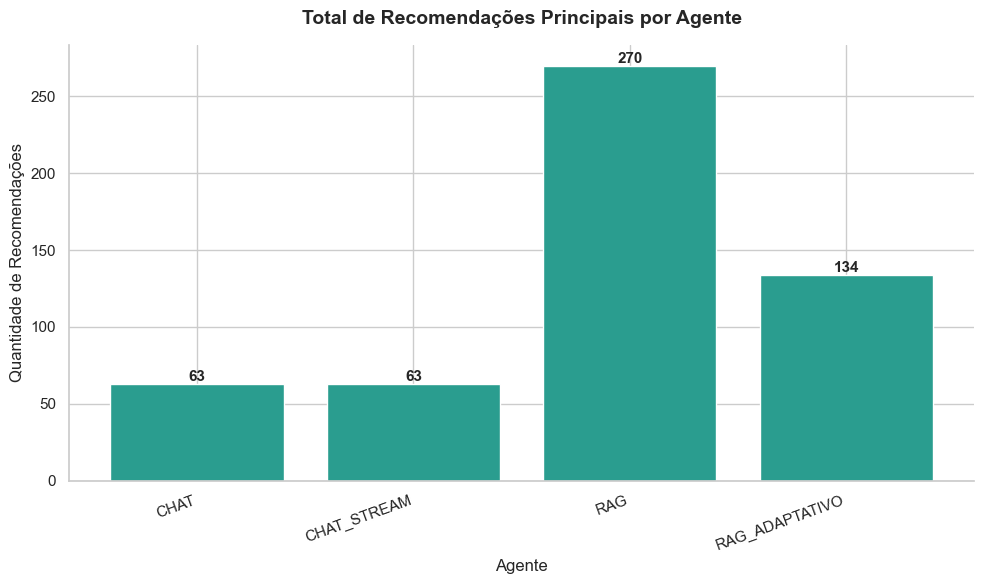

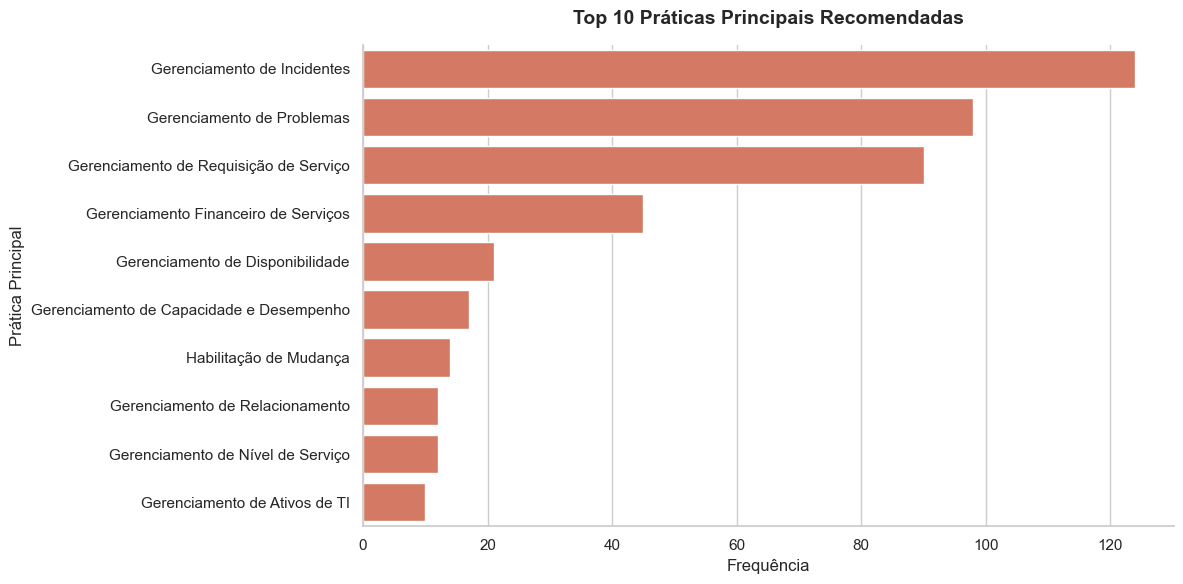

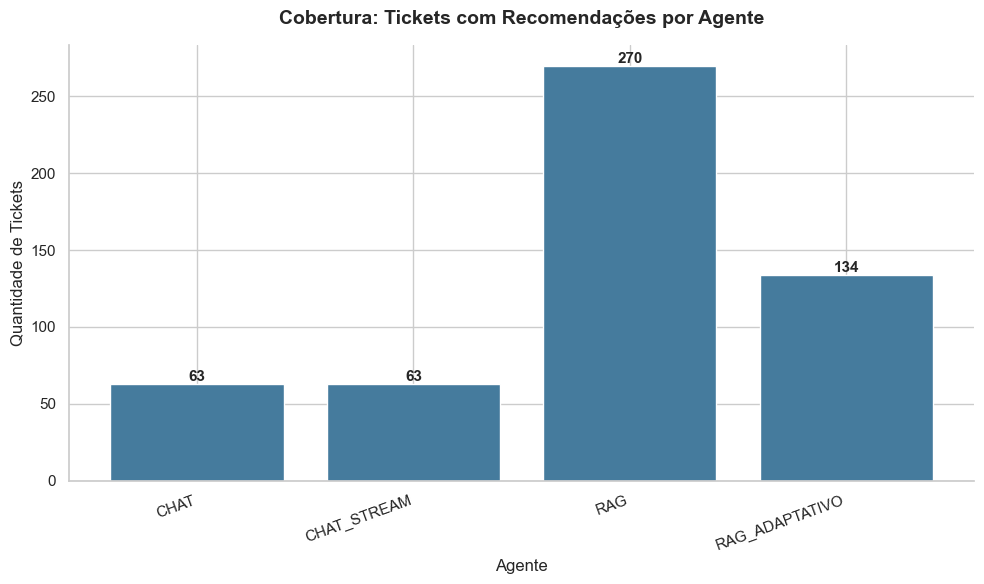

In [27]:
import seaborn as sns

import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")

# 1. Contagem de recomendações por agente
colunas_agentes = [c for c in respostas_tickets.columns if c.endswith('_pratica_principal')]
agentes_nomes = [c.replace('_pratica_principal', '').upper() for c in colunas_agentes]

contagem_recomendacoes = {}
for col, nome in zip(colunas_agentes, agentes_nomes):
    total = respostas_tickets[col].notna().sum()
    contagem_recomendacoes[nome] = total

df_contagem = pd.DataFrame(list(contagem_recomendacoes.items()), columns=['Agente', 'Recomendações'])

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(df_contagem['Agente'], df_contagem['Recomendações'], color='#2a9d8f')
ax.bar_label(bars, fmt='%d', fontsize=11, fontweight='bold')
plt.title('Total de Recomendações Principais por Agente', fontsize=14, fontweight='bold', pad=15)
plt.ylabel('Quantidade de Recomendações', fontsize=12)
plt.xlabel('Agente', fontsize=12)
plt.xticks(rotation=20, ha='right')
sns.despine()
plt.tight_layout()
plt.show()

# 2. Distribuição de práticas principais mais comuns
praticas_principais = []
for col in colunas_agentes:
    praticas_principais.extend(respostas_tickets[col].dropna().values)

df_praticas = pd.Series(praticas_principais).value_counts().head(10).reset_index()
df_praticas.columns = ['Prática Principal', 'Frequência']

fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(data=df_praticas, y='Prática Principal', x='Frequência', ax=ax, color='#e76f51')
plt.title('Top 10 Práticas Principais Recomendadas', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Frequência', fontsize=12)
plt.ylabel('Prática Principal', fontsize=12)
sns.despine()
plt.tight_layout()
plt.show()

# 3. Matriz de cobertura: Tickets com resposta por agente
colunas_pratica = [c for c in respostas_tickets.columns if '_pratica_principal' in c or '_praticas_apoio' in c]
agentes_unicos = set(c.split('_pratica')[0] for c in colunas_pratica)

cobertura_matriz = {}
for agente in sorted(agentes_unicos):
    cols_agente = [c for c in colunas_pratica if c.startswith(agente)]
    tem_resposta = respostas_tickets[cols_agente].notna().any(axis=1).sum()
    cobertura_matriz[agente.upper()] = tem_resposta

df_cobertura = pd.DataFrame(list(cobertura_matriz.items()), columns=['Agente', 'Tickets com Resposta'])

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(df_cobertura['Agente'], df_cobertura['Tickets com Resposta'], color='#457b9d')
ax.bar_label(bars, fmt='%d', fontsize=11, fontweight='bold')
plt.title('Cobertura: Tickets com Recomendações por Agente', fontsize=14, fontweight='bold', pad=15)
plt.ylabel('Quantidade de Tickets', fontsize=12)
plt.xlabel('Agente', fontsize=12)
plt.xticks(rotation=20, ha='right')
sns.despine()
plt.tight_layout()
plt.show()

,agente,total_tickets,tickets_com_resposta,cobertura_pct,acerto_pct,parcial_pct,erro_pct,sem_avaliacao_pct,score_ponderado_pct,acertos,parciais,erros,sem_avaliacao
0,CHAT,270,63,23.333333,26.984127,23.809524,49.206349,76.666667,38.888889,17,15,31,207
1,CHAT STREAM,270,63,23.333333,28.571429,20.634921,50.793651,76.666667,38.888889,18,13,32,207
2,RAG ADAPTATIVO,270,134,49.629630,17.164179,20.149254,62.686567,50.370370,27.238806,23,27,84,136
3,RAG,270,270,100.000000,2.222222,18.518519,79.259259,0.000000,11.481481,6,50,214,0


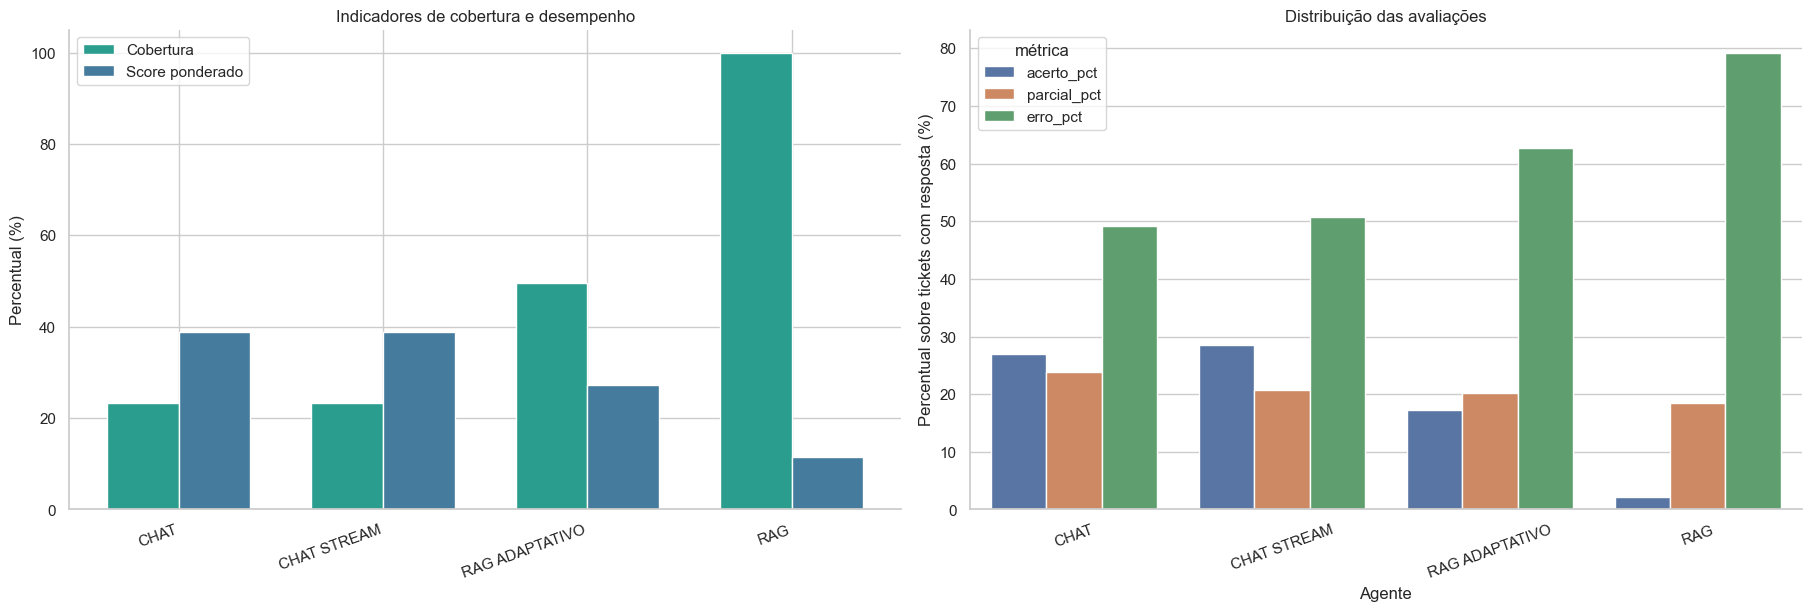

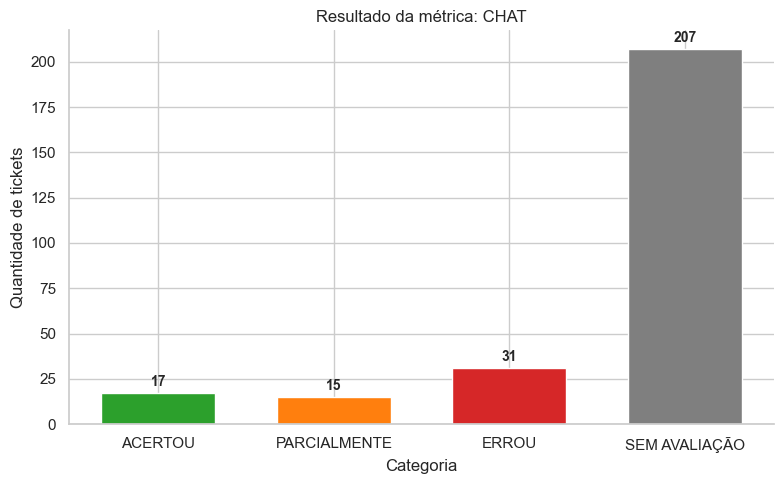

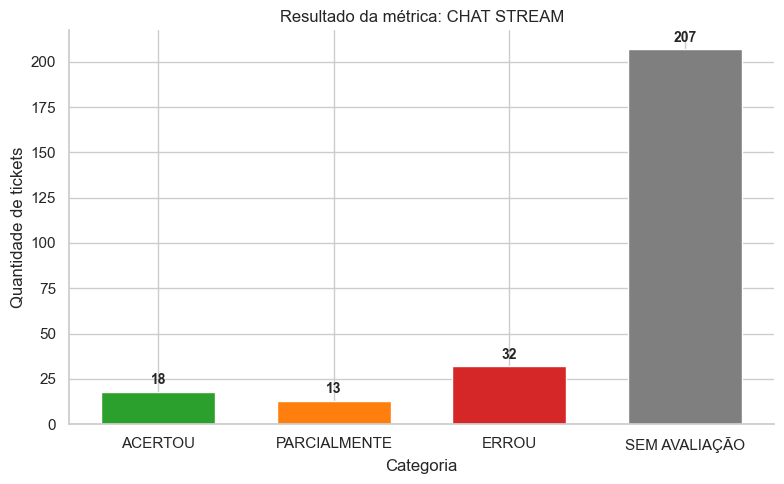

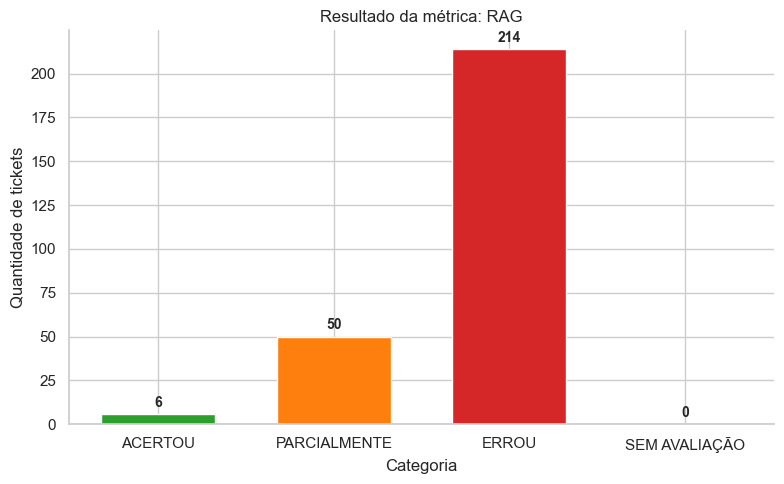

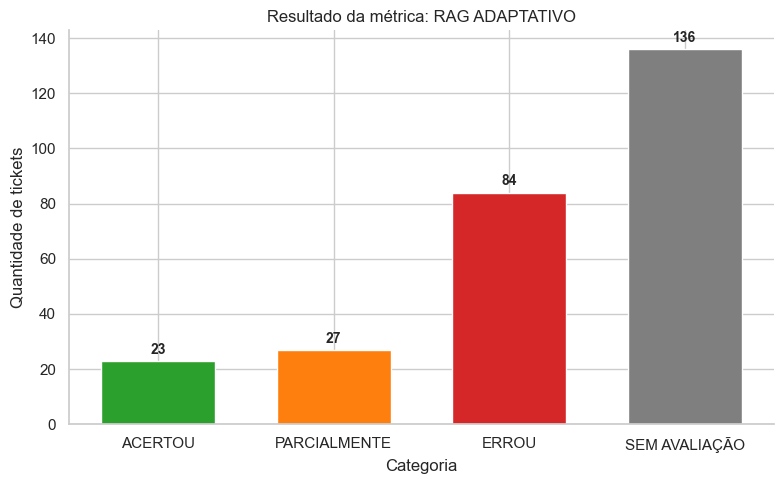

In [28]:
# Indicadores e plotagens por métrica de avaliação encontrada

base_metricas = None
if "respostas_tickets" in globals() and isinstance(respostas_tickets, pd.DataFrame):
    base_metricas = respostas_tickets.copy()
elif "df_avaliacoes" in globals() and isinstance(df_avaliacoes, pd.DataFrame):
    base_metricas = df_avaliacoes.copy()
else:
    raise NameError("Nenhum DataFrame de avaliação encontrado.")

colunas_avaliacao = [c for c in base_metricas.columns if "avaliacao" in c.lower()]
if not colunas_avaliacao:
    raise KeyError("Nenhuma coluna de avaliação encontrada.")

def _nome_agente(col: str) -> str:
    nome = col.lower().replace("avaliacao respostas - ", "").replace("_avaliacao", "")
    nome = nome.replace("_", " ").replace("-", " ")
    nome = re.sub(r"\s+", " ", nome).strip()
    return nome.upper()

def _colunas_resposta_do_agente(df: pd.DataFrame, coluna_avaliacao: str) -> list[str]:
    prefixo = coluna_avaliacao.replace("_avaliacao", "")
    candidatos = [
        c for c in df.columns
        if c.startswith(prefixo) and ("_pratica_principal" in c or "_praticas_apoio" in c)
    ]
    return candidatos

ordem_categorias = ["ACERTOU", "PARCIALMENTE", "ERROU", "SEM AVALIAÇÃO"]

linhas = []
for col_av in colunas_avaliacao:
    nome = _nome_agente(col_av)
    col_resp = _colunas_resposta_do_agente(base_metricas, col_av)

    if col_resp:
        tem_resposta = base_metricas[col_resp].replace(r"^\s*$", pd.NA, regex=True).notna().any(axis=1)
    else:
        tem_resposta = pd.Series(True, index=base_metricas.index)

    serie = base_metricas[col_av].astype("string").fillna("SEM AVALIAÇÃO").str.upper().str.strip()
    contagem = serie.value_counts()

    total = len(base_metricas)
    total_resposta = int(tem_resposta.sum())

    acerto = int(contagem.get("ACERTOU", 0))
    parcial = int(contagem.get("PARCIALMENTE", 0))
    erro = int(contagem.get("ERROU", 0))
    sem_aval = int(contagem.get("SEM AVALIAÇÃO", 0))

    cobertura_pct = (total_resposta / total * 100) if total else 0
    acerto_pct = (acerto / total_resposta * 100) if total_resposta else 0
    parcial_pct = (parcial / total_resposta * 100) if total_resposta else 0
    erro_pct = (erro / total_resposta * 100) if total_resposta else 0
    sem_aval_pct = (sem_aval / total * 100) if total else 0
    score_ponderado_pct = ((acerto + 0.5 * parcial) / total_resposta * 100) if total_resposta else 0

    linhas.append({
        "agente": nome,
        "total_tickets": total,
        "tickets_com_resposta": total_resposta,
        "cobertura_pct": cobertura_pct,
        "acerto_pct": acerto_pct,
        "parcial_pct": parcial_pct,
        "erro_pct": erro_pct,
        "sem_avaliacao_pct": sem_aval_pct,
        "score_ponderado_pct": score_ponderado_pct,
        "acertos": acerto,
        "parciais": parcial,
        "erros": erro,
        "sem_avaliacao": sem_aval,
    })

df_indicadores = pd.DataFrame(linhas).sort_values("score_ponderado_pct", ascending=False).reset_index(drop=True)
display(df_indicadores)

# Gráfico 1: indicadores principais por agente
fig, axes = plt.subplots(1, 2, figsize=(18, 6), constrained_layout=True)

x = range(len(df_indicadores))
largura = 0.35

axes[0].bar([i - largura / 2 for i in x], df_indicadores["cobertura_pct"], width=largura, label="Cobertura", color="#2a9d8f")
axes[0].bar([i + largura / 2 for i in x], df_indicadores["score_ponderado_pct"], width=largura, label="Score ponderado", color="#457b9d")
axes[0].set_title("Indicadores de cobertura e desempenho")
axes[0].set_ylabel("Percentual (%)")
axes[0].set_xticks(list(x))
axes[0].set_xticklabels(df_indicadores["agente"], rotation=20, ha="right")
axes[0].legend()

df_melt = df_indicadores.melt(
    id_vars="agente",
    value_vars=["acerto_pct", "parcial_pct", "erro_pct"],
    var_name="métrica",
    value_name="percentual",
)

sns.barplot(data=df_melt, x="agente", y="percentual", hue="métrica", ax=axes[1])
axes[1].set_title("Distribuição das avaliações")
axes[1].set_ylabel("Percentual sobre tickets com resposta (%)")
axes[1].set_xlabel("Agente")
axes[1].tick_params(axis="x", rotation=20)
sns.despine()
plt.show()

# Gráfico 2: uma plotagem por métrica encontrada
cores = {
    "ACERTOU": "#2ca02c",
    "PARCIALMENTE": "#ff7f0e",
    "ERROU": "#d62728",
    "SEM AVALIAÇÃO": "#7f7f7f",
}

for col_av in colunas_avaliacao:
    nome = _nome_agente(col_av)
    serie = base_metricas[col_av].astype("string").fillna("SEM AVALIAÇÃO").str.upper().str.strip()
    contagem = serie.value_counts().reindex(ordem_categorias).fillna(0).astype(int)

    fig, ax = plt.subplots(figsize=(8, 5))
    barras = ax.bar(contagem.index, contagem.values, color=[cores.get(c, "#333333") for c in contagem.index], width=0.65)
    ax.bar_label(barras, padding=3, fontsize=10, fontweight="bold")
    ax.set_title(f"Resultado da métrica: {nome}")
    ax.set_xlabel("Categoria")
    ax.set_ylabel("Quantidade de tickets")
    sns.despine()
    plt.tight_layout()
    plt.show()